In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
#Memanggil data dari cell yang pertama
df = pd.read_csv('penjualan_kopi_2021_2023.csv', sep=';')
print("Penjualan Kopi Nangkau")

display(df.head(10))


baris, kolom = df.shape
print(f"Jumlah Baris: {baris}")
print(f"Jumlah Kolom: {kolom}")

jumlah_duplikat = df.duplicated().sum()
print(f"Jumlah Baris Duplikat: {jumlah_duplikat}")

print("\nMissing Value\n")

missing_values = df.isnull().sum()
print(missing_values)


print(df[['Unit_Terjual', 'Harga_Per_Unit']].dtypes)

Penjualan Kopi Nangkau


,Tahun,Bulan,Tanggal,Produk,Unit_Terjual,Harga_Per_Unit
0,2021,Januari,1,Americano,52.0,21000.0
1,2021,Januari,1,Cappuccino,45.0,NaN
2,2021,Januari,1,Croissant,20.0,NaN
3,2021,Januari,1,Donat,20.0,15000.0
4,2021,Januari,1,Espresso,43.0,22000.0
5,2021,Januari,1,Latte,38.0,28000.0
6,2021,Januari,2,Americano,44.0,21000.0
7,2021,Januari,2,Cappuccino,36.0,NaN
8,2021,Januari,2,Croissant,18.0,18000.0
9,2021,Januari,2,Croissant,18.0,18000.0


Jumlah Baris: 6600
Jumlah Kolom: 6
Jumlah Baris Duplikat: 19

Missing Value

Tahun               0
Bulan               0
Tanggal             0
Produk            500
Unit_Terjual      500
Harga_Per_Unit    500
dtype: int64
Unit_Terjual      float64
Harga_Per_Unit    float64
dtype: object


In [4]:
df.dropna(subset=['Produk', 'Harga_Per_Unit'], how='all', inplace=True)

df.dropna(subset=['Unit_Terjual'], inplace=True)

harga_dasar_2021 = {
    'Espresso': 22000,
    'Latte': 28000,
    'Cappuccino': 25000,
    'Americano': 21000,
    'Croissant': 18000,
    'Donat': 15000
}

#Mengisi HARGA yang kosong berdasarkan PRODUK dan TAHUN
def hitung_harga_tahunan(row):
    if pd.isnull(row['Harga_Per_Unit']):
        produk = row['Produk']
        tahun = int(row['Tahun'])

        if produk in harga_dasar_2021:
            selisih_tahun = tahun - 2021
            faktor_kenaikan = 1 + (selisih_tahun * 0.02)

            return int(harga_dasar_2021[produk] * faktor_kenaikan)
    return row['Harga_Per_Unit']

df['Harga_Per_Unit'] = df.apply(hitung_harga_tahunan, axis=1)


#Mengisi PRODUK yang kosong berdasarkan HARGA dan TAHUN
def tebak_produk_dari_harga(row):
    if pd.isnull(row['Produk']):
        harga_sekarang = row['Harga_Per_Unit']
        tahun = int(row['Tahun'])
        selisih_tahun = tahun - 2021
        faktor_kenaikan = 1 + (selisih_tahun * 0.02)

        for produk, h_dasar in harga_dasar_2021.items():
            harga_prediksi = int(h_dasar * faktor_kenaikan)
            if harga_prediksi == int(harga_sekarang):
                return produk
    return row['Produk']

df['Produk'] = df.apply(tebak_produk_dari_harga, axis=1)

df = df[df['Unit_Terjual'] >= 0]

df.drop_duplicates(inplace=True)

df['Unit_Terjual'] = df['Unit_Terjual'].astype(int)
df['Harga_Per_Unit'] = df['Harga_Per_Unit'].astype(int)

print("Data Hasil Cleaning")
print(f"Jumlah Baris Sekarang: {df.shape[0]}")
print("\nSisa Missing Value per Kolom:")
print(df.isnull().sum())
print("\nReview beberapa baris data teratas:")
display(df.head(5))

Data Hasil Cleaning
Jumlah Baris Sekarang: 6041

Sisa Missing Value per Kolom:
Tahun             0
Bulan             0
Tanggal           0
Produk            0
Unit_Terjual      0
Harga_Per_Unit    0
dtype: int64

Review beberapa baris data teratas:


,Tahun,Bulan,Tanggal,Produk,Unit_Terjual,Harga_Per_Unit
0,2021,Januari,1,Americano,52,21000
1,2021,Januari,1,Cappuccino,45,25000
2,2021,Januari,1,Croissant,20,18000
3,2021,Januari,1,Donat,20,15000
4,2021,Januari,1,Espresso,43,22000


In [5]:
df['Pendapatan'] = df['Unit_Terjual'] * df['Harga_Per_Unit']

nama_bulan = {
    'Januari': '01',
    'Februari': '02',
    'Maret': '03',
    'April': '04',
    'Mei': '05',
    'Juni': '06',
    'Juli': '07',
    'Agustus': '08',
    'September': '09',
    'Oktober': '10',
    'November': '11',
    'Desember': '12'
}

df['Bulan_Angka'] = df['Bulan'].map(nama_bulan)
df['Tanggal_String'] = df['Tanggal'].astype(str).str.zfill(2)
df['Tanggal_Gabung'] = df['Tahun'].astype(str) + '-' + df['Bulan_Angka'] + '-' + df['Tanggal_String']
df['Tanggal_Penjualan'] = pd.to_datetime(df['Tanggal_Gabung'])
df.drop(columns=['Bulan_Angka', 'Tanggal_String', 'Tanggal_Gabung'], inplace=True)

print('Display')
print(df[['Pendapatan', 'Tanggal_Penjualan']].dtypes)
display(df.head(5))

Display
Pendapatan                    int64
Tanggal_Penjualan    datetime64[us]
dtype: object


,Tahun,Bulan,Tanggal,Produk,Unit_Terjual,Harga_Per_Unit,Pendapatan,Tanggal_Penjualan
0,2021,Januari,1,Americano,52,21000,1092000,2021-01-01
1,2021,Januari,1,Cappuccino,45,25000,1125000,2021-01-01
2,2021,Januari,1,Croissant,20,18000,360000,2021-01-01
3,2021,Januari,1,Donat,20,15000,300000,2021-01-01
4,2021,Januari,1,Espresso,43,22000,946000,2021-01-01



TOTAL UNIT & PENDAPATAN PER PRODUK


,Produk,Unit_Terjual,Pendapatan
0,Americano,"39,265","Rp 840,748,020"
1,Cappuccino,"39,859","Rp 1,016,256,000"
2,Croissant,"21,360","Rp 392,115,960"
3,Donat,"22,379","Rp 342,290,700"
4,Espresso,"39,504","Rp 886,519,480"
5,Latte,"39,528","Rp 1,128,724,240"



RATA-RATA UNIT TERJUAL PER HARI (TIAP PRODUK & TAHUN)


,Tahun,Produk,Rata_Rata_Harian
0,2021,Americano,40.07 unit
1,2021,Cappuccino,39.39 unit
2,2021,Croissant,21.36 unit
3,2021,Donat,22.19 unit
4,2021,Espresso,40.29 unit
5,2021,Latte,39.56 unit
6,2022,Americano,38.21 unit
7,2022,Cappuccino,39.67 unit
8,2022,Croissant,21.55 unit
9,2022,Donat,22.31 unit



PRODUK TERLARIS PER TAHUN


,Tahun,Produk,Unit_Terjual
0,2021,Americano,"13,504 unit"
1,2022,Cappuccino,"13,368 unit"
2,2023,Espresso,"13,248 unit"



GRAFIK BATANG


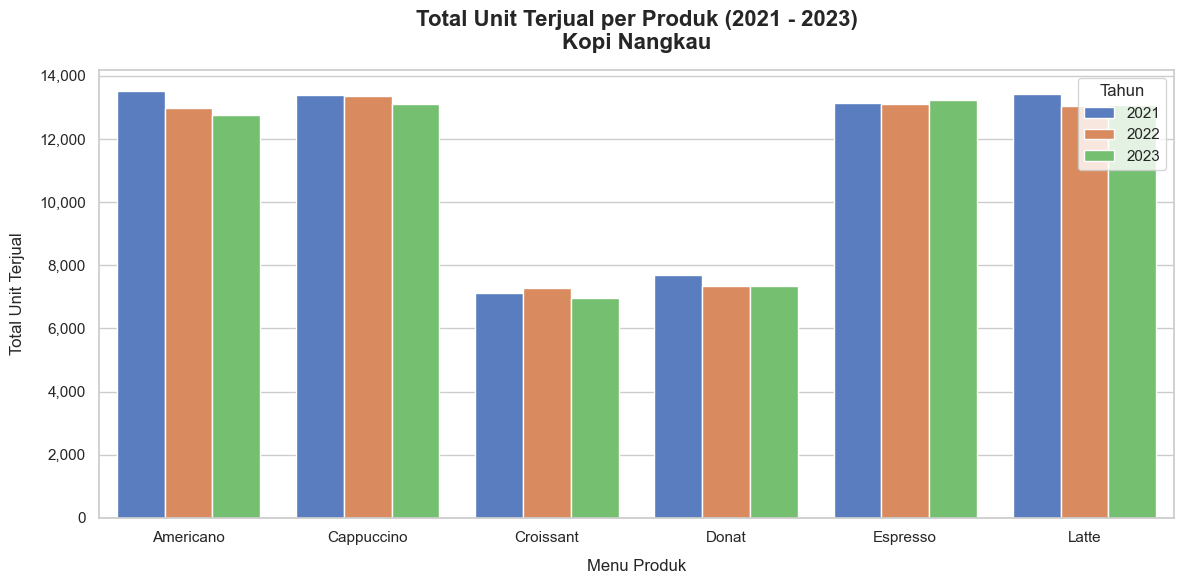

In [6]:
sns.set_theme(style="whitegrid")

print("\nTOTAL UNIT & PENDAPATAN PER PRODUK") # TUP
TUP = df.groupby('Produk')[['Unit_Terjual', 'Pendapatan']].sum().reset_index()
display(TUP.style.format({'Unit_Terjual': '{:,}', 'Pendapatan': 'Rp {:,.0f}'}))

print("\nRATA-RATA UNIT TERJUAL PER HARI (TIAP PRODUK & TAHUN)") #RUTPH
total_per_hari = df.groupby(['Tahun', 'Produk', 'Tanggal_Penjualan'])['Unit_Terjual'].sum().reset_index()
RUTPH = total_per_hari.groupby(['Tahun', 'Produk'])['Unit_Terjual'].mean().reset_index()
RUTPH.rename(columns={'Unit_Terjual': 'Rata_Rata_Harian'}, inplace=True)

display(RUTPH.style.format({'Rata_Rata_Harian': '{:.2f} unit'}))

print("\nPRODUK TERLARIS PER TAHUN") #PTPT
total_produk_tahunan = df.groupby(['Tahun', 'Produk'])['Unit_Terjual'].sum().reset_index()

id_terlaris = total_produk_tahunan.groupby('Tahun')['Unit_Terjual'].idxmax()
PTPT = total_produk_tahunan.loc[id_terlaris].reset_index(drop=True)

display(PTPT.style.format({'Unit_Terjual': '{:,} unit'}))

print("\nGRAFIK BATANG")
data_grafik = df.groupby(['Tahun', 'Produk'])['Unit_Terjual'].sum().reset_index()

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=data_grafik,
    x='Produk',
    y='Unit_Terjual',
    hue='Tahun',
    palette='muted'
)

plt.title('Total Unit Terjual per Produk (2021 - 2023)\nKopi Nangkau', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Menu Produk', fontsize=12, labelpad=10)
plt.ylabel('Total Unit Terjual', fontsize=12, labelpad=10)
plt.legend(title='Tahun', loc='upper right')

ax.get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))
plt.tight_layout()
plt.show()